## Project Goal:
Create a model that can accurately predict house prices based on different property features. The goal is to achieve high R² and low RMSE scores, while avoiding overfitting.

---
## Objectives

### Data Preparation and Feature Engineering
- Clean the dataset by handling missing values and adjusting certain features.
- Create new features like all_rooms (total rooms), is_basement (indicator for basement), and waterfront_with_view to add more useful information.
### Feature Selection
- Use methods like correlation matrix and Mutual Information to find the most useful features for predicting house prices.
- Apply model-based techniques like Recursive Feature Elimination (RFE) to further refine the feature set.
### Model Building and Evaluation
- Build different models such as Linear Regression, Decision Tree, and Random Forest to predict house prices.
- Use Polynomial Features and Regularization methods like Ridge and Lasso to improve performance.
- Use GridSearchCV and RandomizedSearchCV to find the best parameters for each model.
### Model Comparison
- Compare the models using evaluation metrics like R² and RMSE to check their accuracy and overfitting.
- Show results with visualizations to see how each model performs on training and test datasets.
### Feature Importance Analysis
- Use Lasso Regression to understand which features have the biggest impact on price.
- Reverse the scaling to see the coefficients in their original units.


----------
## About Dataset

This dataset contains information on various properties, including their characteristics and sale prices. Below is a brief description of each feature:

- `ID`: Unique identifier for each property.
- `Date`: Date of property listing.
- `Price`: Property price in currency.
- `Bedrooms`: Number of bedrooms.
- `Bathrooms`: Number of bathrooms.
- `Sqft Living`: Living area size in square feet.
- `Sqft Lot`: Total lot size in square feet.
- `Floors`: Number of floors.
- `Waterfront`: Indicates if the property has a waterfront view (0 for no, 1 for yes).
- `View`: Quality level of the property view (0 to 4).
- `Condition`: Overall condition rating (1 to 5).
- `Grade`: Overall grade rating (1 to 13).
- `Sqft Above`: Living area above ground level in square feet.
- `Sqft Basement`: Basement area in square feet.
- `Yr Built`: Year the property was built.
- `Yr Renovated`: Year the property was last renovated.
- `Zipcode`: Property location zip code.
- `Lat`: Latitude coordinate of the property location.
- `Long`: Longitude coordinate of the property location.
- `Sqft Living15`: Living area size of 15 nearest properties in square feet.
- `Sqft Lot15`: Lot size of 15 nearest properties in square feet.

### Source : 
- [kaggle.com](https://www.kaggle.com/datasets/sukhmandeepsinghbrar/housing-price-dataset)







---
## Import

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

'Importing Models'
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import RFE, mutual_info_regression, SequentialFeatureSelector
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# Importing and initializing the dataset
df = pd.read_csv('cleaned_housing_data.csv')

# Converting the 'date' column to datetime format
df['date'] = pd.to_datetime(df['date'])

# Creating 'month' and 'year' features from the 'date' column
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

# Remove unwanted columns: 'id', 'date', 'yr_renovated', 'floors'
column_list = [col for col in df.columns if col not in ['id', 'date', 'yr_renovated', 'floors']]
df = df[column_list]

# Feature engineering: Create new columns for analysis
df['view_bool'] = df['view'].astype(bool)  # Convert 'view' to a boolean feature
df['waterfront_with_view'] = df['waterfront'] * df['view_bool']  # Interaction feature for 'waterfront' and 'view'
df['all_rooms'] = df['bathrooms'] + df['bedrooms']  # Total number of rooms
df['is_basement'] = df['sqft_basement'].astype(bool)  # Boolean flag for presence of a basement


### Note 

I decided to add some features to explore different relationships between the variables.
<br><br>
While analyzing the dataset using `latitude`, `longitude`, and Google Maps, I noticed that the `floors` feature could mean either the number of floors in a house or the floor number of an apartment. Since it is difficult to predict which meaning applies in each case, I decided to remove this feature.

---
## Feature Selection
This section focuses on selecting the most valuable features without building a model, using these methods:
- Logical Selection
- Correlation Matrix
- Mutual Information Feature Selection

After selecting features using these methods, we will compare the results with model-based feature selection techniques such as recursive feature elimination (RFE) or Linear regression to see how well the feature set performs in practice.

---
### Logical Selection
The Logical Selection relies on common sense, domain knowledge, and intuition to select features that are most likely to influence the target variable. This approach doesn’t require complex calculations but instead focuses on identifying potential issues and provides a deeper understanding of the data.

Let's take a look at our data. The first features to focus on are `sqft_living` and `sqft_lot`, as they should hold high value for predicting house prices. Additionally, bedrooms and bathrooms are key indicators to consider. It's also important to pay attention to `grade` and `condition`, as they directly reflect the quality and state of the property.

Most interesting might be to explore is the `zip code`, along with `latitude` or `longitude`, combined with `sqft_living15` (living area of nearby properties), which could provide insight into neighborhood influence on pricing.

On the other hand, features like `sqft_lot` and `sqft_lot15` may not offer much predictive power. A large house can have a small lot, and the opposite may happen, which could confuse the model as these features may not consistently explain price differences.

We should also consider the `month` feature, which theoretically could capture seasonal price changes. However, since the time frame in this dataset is quite small (2014-2015), its influence may not be significant.



---
### Correlation matrix
The Correlation Matrix is a powerful tool for identifying the linear (and only linear it's important) relationships between features and the target variable. It helps in understanding which features are positively or negatively correlated with the target, and which features are highly correlated with each other (potentially leading to multicollinearity).

We are going to use the standard correlation method in NumPy, which is the Pearson correlation coefficient. This method measures the linear relationship between two variables and returns a value between `-1` and `1`, where is:
-   __1__ indicates a `perfect positive correlation`.
- __-1__ indicates a `perfect negative correlation`.
-   __0__ indicates `no linear relationship`.

<Axes: >

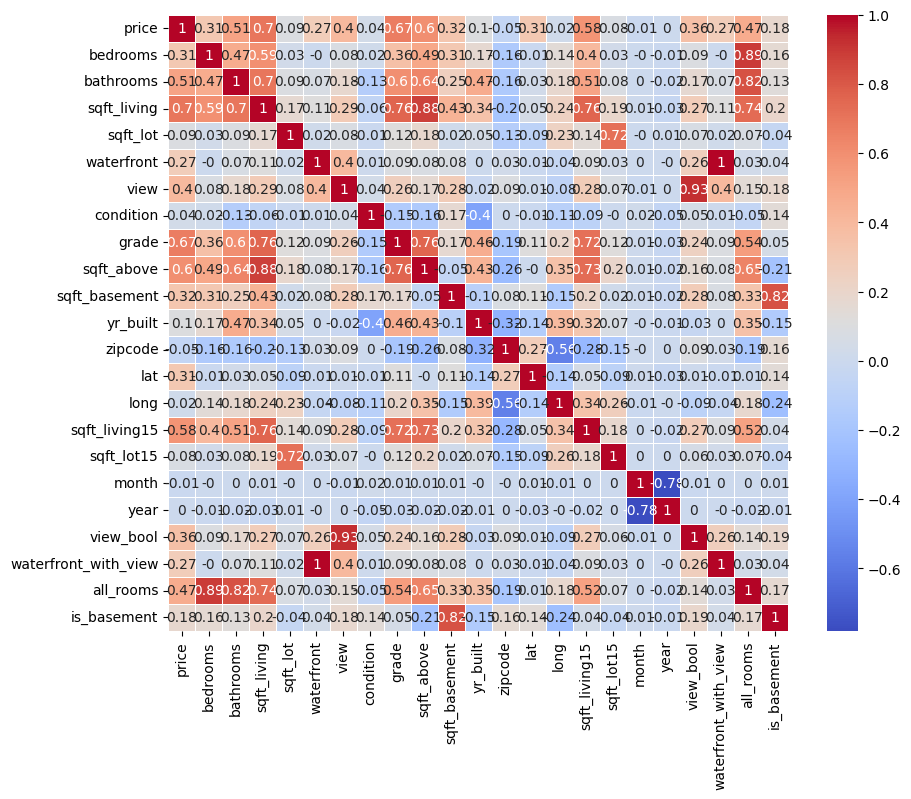

In [4]:
corr_matrix = df.corr() # Building cross correlation table.
corr_matrix = round(corr_matrix, 2) # Making it pretty.

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5) #Building and plotting heatmap for better understanding.

#### Results
After calculating the correlations, we found that some features aligned with our logical selection, confirming their importance. These features show a strong correlation with the target variable, such as: 
- `sqft_living` 
- `grade` 
- `bathrooms` 
- `sqft_living15` 

However, a few features displayed unexpectedly low correlation, which suggests they may not provide as much predictive power as initially thought, such as:
- `condition`
- `sqft_basement`
- `bedrooms`, but we will still keep this feature, because this is essential characteristics of a house.

Additionally, certain features demonstrated signs of multicollinearity, meaning they are highly correlated with other features in the dataset. 
- `sqft_living` shows a strong correlation with `sqft_living15`, `grade`, `sqft_above`(roughly speaking, they are the same), as well as  `bathrooms` and `bedrooms`. Additionally, its correlation with `all_rooms` (the total number of rooms) indicates that number of rooms doesn’t offer many new insights.

Therefore, we must be cautious when using these features, and in some cases, it may be necessary to remove or combine them to avoid this issue (overfitting).

___
### Mutual Information Feature  
This method is a powerful tool for determining how valuable features are for prediction. Unlike the correlation matrix, Mutual Information can capture non-linear relationships between features and the target, providing deeper insights that a simple linear correlation might miss.

However, there are also some drawbacks. Unlike the correlation matrix, Mutual Information does not indicate the direction of the relationship (whether it's positive or negative), making interpretation more challenging. Additionally, it is computationally expensive, which can be an issue when dealing with large datasets.

Moreover, Mutual Information does not reveal multicollinearity — the redundancy between features — so it’s harder to identify highly correlated features that might lead to overfitting a model. For these reasons, in some cases, it may be more efficient to rely on the correlation matrix for quicker insights and multicollinearity detection, especially when working with simpler or smaller datasets.


In [24]:
# Separate features (X) and the target variable (y)
X = df.drop('price', axis=1)  # All features except 'price'
y = df['price']               # Target variable: 'price'

# Calculate the Mutual Information between each feature and the target variable
mi = mutual_info_regression(X, y)

# Create a DataFrame to display the mutual information of each feature
mi_df = pd.DataFrame({'Feature': X.columns, 'Mutual Information': mi})

# Sort the DataFrame by the mutual information values in descending order
mi_df = mi_df.sort_values(by='Mutual Information', ignore_index=True, ascending=False)

# Display the sorted DataFrame
mi_df


,Feature,Mutual Information
0,zipcode,0.417472
1,lat,0.342390
2,sqft_living,0.340315
3,grade,0.336932
4,sqft_living15,0.268847
5,sqft_above,0.251371
6,all_rooms,0.154369
7,bathrooms,0.140321
8,long,0.112900
9,sqft_lot15,0.081810


#### Result
After applying Mutual Information Regression, we can see that location-based features have a huge impact on `price`, as predicted. One of the most interesting findings is that `zip_code`, which previously showed almost `0 correlation` with `price`, is now one of the most valuable features, highlighting its non-linear relationship with the target.

Additionally, features such as `grade`, `sqft_living`, and `all_rooms` (which includes `bathrooms` and `bedrooms`) also demonstrate a strong influence on the target value. 
<br>These results confirm the importance of property characteristics and neighborhood factors in determining house prices.


---
### Additional Test
After analyzing the results from both the correlation matrix and Mutual Information, a few outcomes are surprising. Firstly, the low correlation of `waterfront` and `bedrooms` with the target variable seems unexpected. Secondly, the fact that `zip_code` shows almost zero correlation with price but has a high Mutual Information score.

Because of these questions, I want to further explore the distribution of the data and visualize how the price relates to all the variables. This will help better understand the relationships and provide more understanding of impact on the target in non-linear or unexpected ways.

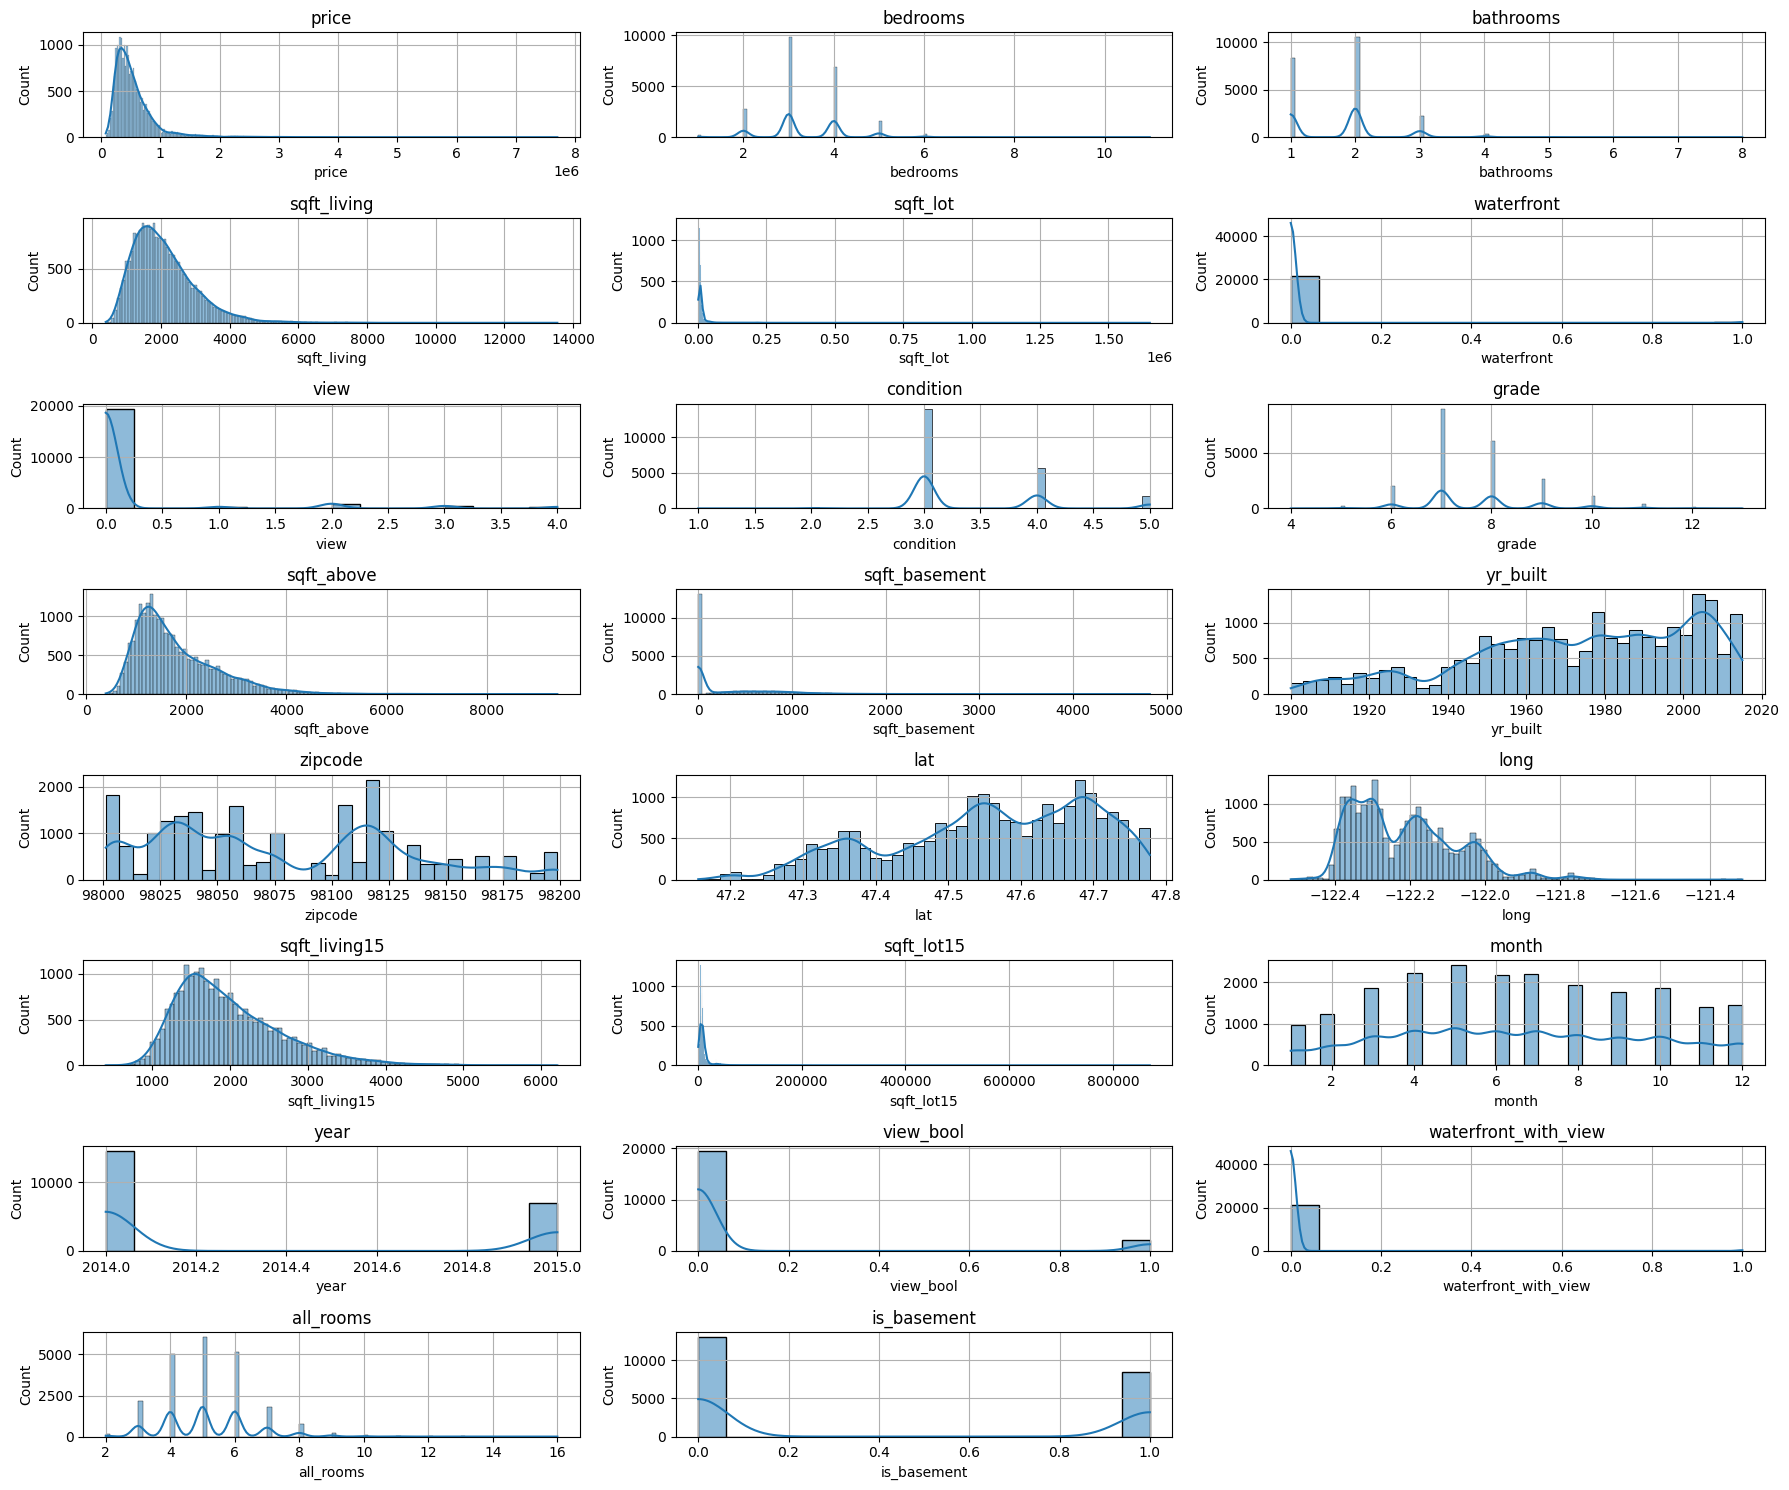

In [39]:
# Determine the number of columns to plot
num_cols = len(df.columns)

# Create a grid with the number of columns and rows based on the total number of features
fig, axes = plt.subplots(nrows=(num_cols // 3) + 1, ncols=3, figsize=(18, 15))  # Adjust rows and cols as needed

# Flatten the axes array to iterate over subplots easily
axes = axes.flatten()

# Plot each feature in its own subplot
for i, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[i])  # Plot the histogram with KDE on the current subplot
    axes[i].set_title(f'{col}')                  # Set the title for each subplot
    axes[i].set_xlabel(col)                      # Set the x-axis label for each subplot
    axes[i].grid(True)

# Remove any empty subplots if the number of columns is not a perfect multiple of rows x columns
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])  # Remove unused subplots

# Adjust layout and display the combined figure
plt.tight_layout()
plt.show()


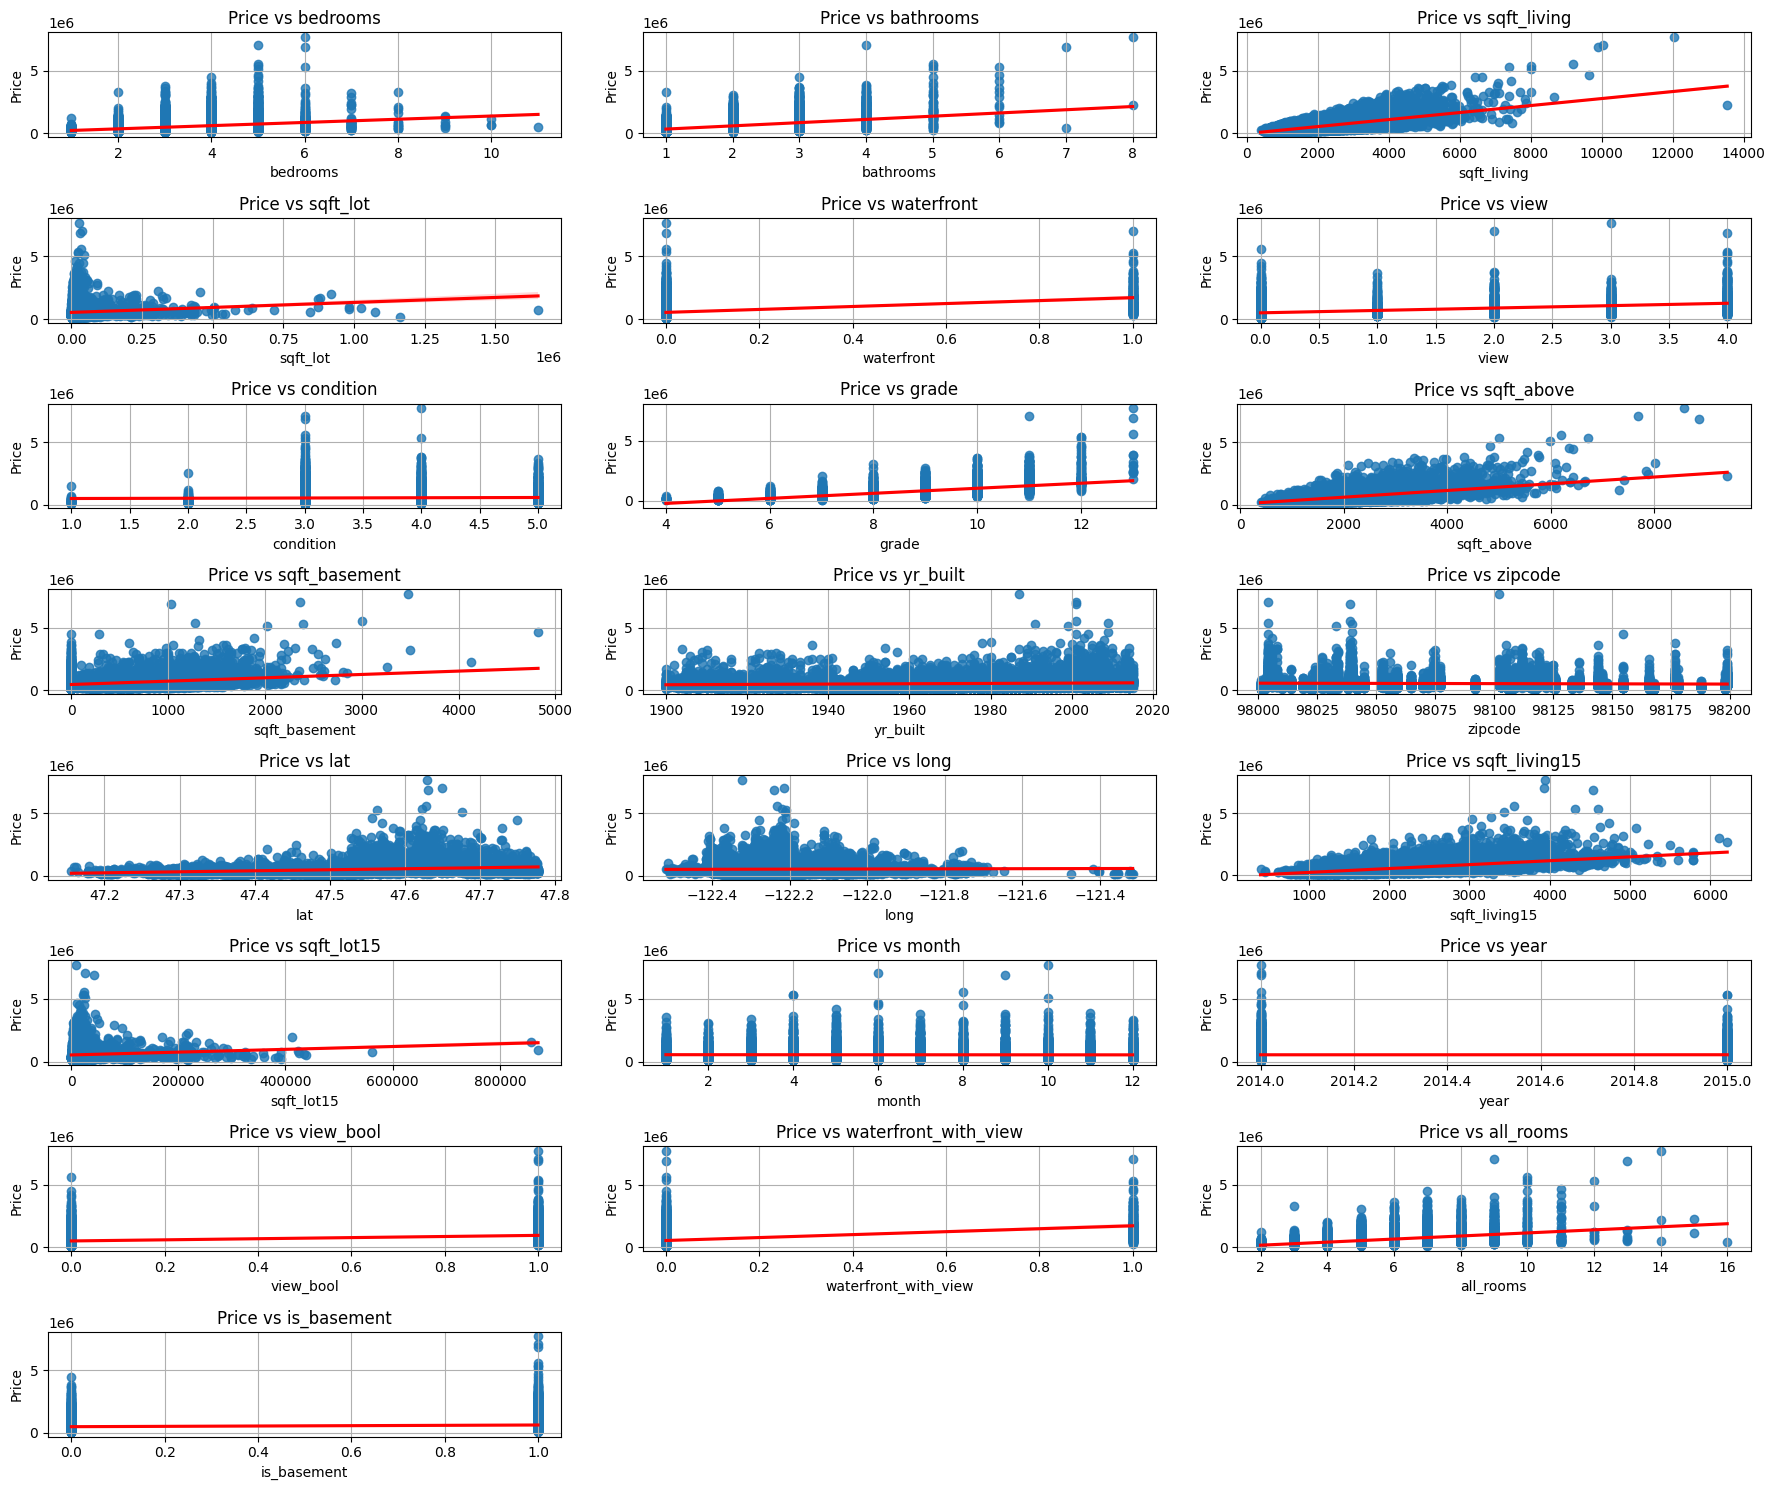

In [40]:
# Determine the number of columns to plot (excluding 'price')
features = [col for col in df.columns if col != 'price']
num_features = len(features)

# Create a grid with the number of rows and columns based on the number of features
fig, axes = plt.subplots(nrows=(num_features // 3) + 1, ncols=3, figsize=(18, 15)) 
# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot each feature against 'price' in its own subplot
for i, col in enumerate(features):
    sns.regplot(x=df[col].astype(float), y=df['price'], scatter=True, line_kws={"color": "red"}, ax=axes[i])
    axes[i].set_title(f'Price vs {col}')  # Set title for each subplot
    axes[i].set_xlabel(col)               # Set x-axis label
    axes[i].set_ylabel('Price')           # Set y-axis label
    axes[i].grid(True)

# Remove any empty subplots if the number of columns is not a perfect multiple of rows x columns
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])  # Remove unused subplots

# Adjust layout and display the combined figure
plt.tight_layout()
plt.show()

### Note
There are some outliers, but I decided to keep them to maintain the full picture of the data.

### Result
The waterfront feature has poor data distribution and almost no linear relationship with price, as does view. These features might not work well in linear models, but could be useful in non-linear models that can handle more complex relationships.

`zip_code` and `latitude` performed well in the Mutual Information analysis. However, `zip_code` is harder to interpret, and its relationship with price isn’t clear, so it might only work in non-linear models. `latitude`, on the other hand, shows a clearer connection with price and can be used in both linear and non-linear models.

The `sqft_living15` is another feature, which describes the neighborhood, has high correlation with other variables. This might cause problems with linear models due to multicollinearity, but it could still provide value in non-linear models. However, `latitude` is a better choice for neighborhood representation because it's simpler and more reliable.



---
### Additional 

However, because some variables are unclear and there is some multicollinearity, it might still be useful to try more advanced methods like Recursive Feature Elimination (RFE) or Sequential Feature Selection. These techniques add or remove features step-by-step to find the most important ones, which helps in refining the feature set.

That said, if the dataset is too big or resources are limited, the previous methods like the correlation matrix and Mutual Information are still good options, as they provide a balance between effectiveness and resource cost.

 ---
 ### Recursive Feature Elimination

In [46]:
# Step 1: Split the dataset into features (X) and target (y)
X = df.drop('price', axis=1)
y = df['price']

# Step 2: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Define the base model (Decision Tree Regressor)
tree = DecisionTreeRegressor(random_state=42)

# Step 4: Define the parameter grid for hyperparameter tuning with cross-validation
param_grid = {
    'estimator__max_depth': [3, 5, 7, 10, 15],          # Maximum depth of the tree
    'estimator__min_samples_split': [2, 5, 10, 15],     # Minimum samples required to split a node
    'estimator__min_samples_leaf': [1, 2, 5, 10],       # Minimum samples required in a leaf node
    'estimator__max_features': [None, 'sqrt', 'log2'],  # Number of features to consider for splitting
    'n_features_to_select': [5, 7, 9, 12],              # Number of features to select with RFE
}

# Step 5: Initialize RFE with the Decision Tree as the base model
rfe = RFE(estimator=tree, step=1)

# Step 6: Set up GridSearchCV for tuning RFE and Decision Tree hyperparameters
grid_search = GridSearchCV(
    estimator=rfe,
    param_grid=param_grid,
    scoring='r2',  # Evaluate model using R² score
    cv=5,          # 5-fold cross-validation
)

# Step 7: Train GridSearchCV on the training data
grid_search.fit(X_train, y_train)

# Step 8: Retrieve the best hyperparameters
best_params = grid_search.best_params_

# Step 9: Train the model with the best hyperparameters on the training data
best_rfe = grid_search.best_estimator_
y_pred_train = best_rfe.predict(X_train)
y_pred_test = best_rfe.predict(X_test)

# Step 10: Evaluate the model on training and test data
train_score = r2_score(y_train, y_pred_train)
test_score = r2_score(y_test, y_pred_test)

# Print the results
print(f"Best Parameters: {best_params}")
print(f"Training R² Score: {train_score}")
print(f"Test R² Score: {test_score}")

Best Parameters: {'estimator__max_depth': 10, 'estimator__max_features': None, 'estimator__min_samples_leaf': 2, 'estimator__min_samples_split': 2, 'n_features_to_select': 7}
Training R² Score: 0.8993185470466131
Test R² Score: 0.7590314257928756


In [49]:
# Get the mask of selected features (True for selected features)
selected_features_mask = best_rfe.support_  

# Retrieve the names of selected features
selected_features = X.columns[selected_features_mask]  

# Get the ranking of all features (1 — selected feature)
ranking = best_rfe.ranking_  

print(f"Selected Features: {list(selected_features)}")

feature_ranking = pd.DataFrame({
    'Feature': X.columns,
    'Selected': selected_features_mask,
    'Ranking': ranking
})

# Print feature ranking sorted by ranking value
print("Feature Ranking:")
print(feature_ranking.sort_values(by='Ranking'))


Selected Features: ['sqft_living', 'waterfront', 'grade', 'sqft_above', 'lat', 'long', 'sqft_living15']
Feature Ranking:
                 Feature  Selected  Ranking
8             sqft_above      True        1
2            sqft_living      True        1
4             waterfront      True        1
14         sqft_living15      True        1
7                  grade      True        1
13                  long      True        1
12                   lat      True        1
15            sqft_lot15     False        2
11               zipcode     False        3
5                   view     False        4
3               sqft_lot     False        5
19  waterfront_with_view     False        6
20             all_rooms     False        7
9          sqft_basement     False        8
10              yr_built     False        9
16                 month     False       10
1              bathrooms     False       11
6              condition     False       12
0               bedrooms     False       13

In [48]:
# Step 1: Split the data into features (X) and target variable (y)
X = df.drop('price', axis=1)
y = df['price']

# Step 2: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Define the base model (Linear Regression)
linear = LinearRegression()

# Step 4: Define a pipeline with polynomial features, scaling, and RFE
pipe = Pipeline([
    ('scaler', StandardScaler()),  
    ('feature_selector', SequentialFeatureSelector(estimator=linear, direction='forward')),  # Feature Selection
    ('model', linear) 
])

# Step 5: Define parameter grid for tuning with GridSearchCV
param_grid = {
    "scaler": [StandardScaler()],                                                 # Use StandardScaler for scaling
    'feature_selector__n_features_to_select': range(1, X_train.shape[1] + 1, 4),  # Number of features to select
    'feature_selector__direction': ['forward'],                                   # Use forward selection strategy
}

# Step 6: Set up GridSearchCV to find the best parameters
grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='r2',  # Evaluate the model using R² score
    cv=3           # 3-fold cross-validation
)

# Step 7: Train GridSearchCV on the training data
grid_search.fit(X_train, y_train)

# Step 8: Retrieve the best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)

# Step 9: Train the model with the best parameters on the training data
best_model = grid_search.best_estimator_
y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

# Step 10: Evaluate the model on training and test data
train_score = r2_score(y_train, y_pred_train)
test_score = r2_score(y_test, y_pred_test)

print(f"R² on training data: {train_score}")
print(f"R² on test data: {test_score}")


Best Parameters: {'feature_selector__direction': 'forward', 'feature_selector__n_features_to_select': 21, 'scaler': StandardScaler()}
R² on training data: 0.6924902400597128
R² on test data: 0.702643760111882


## Note
I will not consider the results from RFE, as it’s not logical to select all features, because it leads to overfitting. The reason overfitting might not occur in the case of RFE is likely due to a low-quality dataset, which results in similar performance even on the test data.

In the future, features for linear models will be selected based on the correlation matrix and my own reasoning.

---
## Result

We used RFE with a decision tree instead of linear regression because we noticed some non-linear relationships between the features and the target. As a result, we saw some interesting outcomes: waterfront and longitude had a strong impact, while `zipcode` performed slightly worse compared to `lat`, `long`, `sqft_living`, and `sqft_lot15`. `Bathrooms` and `bedrooms`, on the other hand, showed weak results.

Another surprising outcome was that `sqft_lot15` performed better than `sqft_lot`. The best number of features was 7, which means that 9 features are too many and 5 are too few. This suggests that adding an 8th feature, like `sqft_lot15`, might improve the model.

`Sqft_above` also performed well, even though it is just `sqft_living` minus `sqft_basement`. It might provide extra information about the relationship between these two features.

It’s important to mention that RFE and Mutual Information (MI) gave different results. MI measures each feature’s relationship with the target separately, while RFE considers hidden dependencies between the features. However, using too many features can still lead to overfitting.

The correlation matrix worked well for finding linear relationships but cannot detect non-linear ones.


---
## Conclusion
Even though RFE is a more computationally intensive process, MI + correlation matrix provided similar results if we disregard `bedrooms`, `bathrooms`, and `waterfront`.

In the future, if we decide to use non-linear models, the feature set will be:
- `sqft_living`
- `waterfront`
- `grade`
- `sqft_above`
- `lat`
- `long`
- `sqft_living15`
- `sqft_lot15`
<br><br>
On the other hand, when using linear models, we must keep in mind multicollinearity and the fact that linear models effectively capture only linear relationships. Thus, we will choose the following features:
<br><br>
- `bedrooms`

- `bathrooms`
- `sqft_living` 
- `grade`
- `lat`
- `long` 
- `waterfront`

---
## Models tuning

In this section, I will tune hyperparameters and choose optimization methods using GridSearchCV and RandomSearchCV. The selection criteria will be based on R² (the higher, the better). However, to prevent overfitting, the difference between test and training scores should be around 0.15 (which indicates moderate overfitting) and ideally less than 0.1.

---
### Linear Model

In [ ]:
# Feature selection for analysis
df_liner = df[['price', 'bedrooms', 'bathrooms', 'sqft_living', 'grade', 'lat', 'long', 'waterfront']]

# Feature selection for analysis
X = df_liner.drop('price', axis=1)  
y = df_liner['price']               

# Step 2: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Define a pipeline with polynomial features and scaling for each model
pipeline = Pipeline([
    ("poly", PolynomialFeatures()),   
    ("scaler", StandardScaler()),    
    ("model", LinearRegression())     
])

# Step 4: Define parameter grid for tuning with GridSearchCV
param_grid = [
    # Polynomial features + Linear Regression
    {
        "poly__degree": [1, 2, 3],                   # Different polynomial degrees
        "scaler": [StandardScaler(), None],          # Apply scaling or not
        "model": [LinearRegression()]                # Regular Linear Regression
    },
    # Polynomial features + Ridge Regression
    {
        "poly__degree": [1, 2, 3],                   # Polynomial degrees for Ridge Regression
        "scaler": [StandardScaler(), None],          # Apply scaling or not
        "model": [Ridge()],                          # Use Ridge Regression
        "model__alpha": [0.1, 1, 10, 100]            # Regularization parameters for Ridge
    }
]

# Step 5: Define scoring metrics for model evaluation
scoring = {
    'MSE': 'neg_root_mean_squared_error',  # Mean Squared Error (negative for minimizing)
    'R2': 'r2'                             # Coefficient of determination (R²)
}

# Step 6: Set up GridSearchCV to find the best parameters
grid = GridSearchCV(
    estimator=pipeline,        
    param_grid=param_grid,     
    scoring=scoring,           
    refit='R2',                # Metric to optimize for refitting
    cv=3,                      # 3-fold cross-validation
    return_train_score=True    # Store training scores
)

# Step 7: Train GridSearchCV on the training data
grid.fit(X_train, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {grid.best_params_}")
print(f"Best R² Score: {grid.best_score_:.4f}")

In [13]:
# Let's take a closer look at the results
cv_results = pd.DataFrame(grid.cv_results_)
cv_results['rank'] = cv_results['mean_train_R2'] - cv_results['mean_test_R2']

cv_results [ ['param_model', 'param_poly__degree', 'param_scaler', 'param_model__alpha',
               'mean_test_MSE', 'mean_train_MSE', 'mean_test_R2',  'mean_train_R2', 'rank']].sort_values('mean_test_R2', ascending= False).head(n=5)

,param_model,param_poly__degree,param_scaler,param_model__alpha,mean_test_MSE,mean_train_MSE,mean_test_R2,mean_train_R2,rank
4,LinearRegression(),3,StandardScaler(),NaN,-175650.297805,-155176.052953,0.774076,0.824121,0.050045
2,LinearRegression(),2,StandardScaler(),NaN,-181285.460593,-177540.828868,0.759635,0.769758,0.010123
3,LinearRegression(),2,None,NaN,-181285.460596,-177540.828868,0.759635,0.769758,0.010123
9,Ridge(),2,None,0.1,-182652.380526,-179327.180354,0.756014,0.765108,0.009094
5,LinearRegression(),3,None,NaN,-183094.581352,-161422.507834,0.754931,0.809531,0.054600


#### Result

As a result, we can see that the best performance was achieved by `Linear Regression` with `polynomial degree 3` and `standardization`. However, I prefer `Linear Regression` with `polynomial degree 2` because it has much less overfitting. I would choose it without `standardization`, as its results are similar to the standardized version.

It is also interesting to note that `polynomial degree 3` with `standardization` reduced overfitting, unlike with `polynomial degree 2`.

---
### Decision Tree Model

In [10]:
# Feature selection for analysis
df_tree = df[['price','sqft_living', 'waterfront', 'grade', 'sqft_above', 'lat', 'long', 'sqft_living15', 'sqft_lot15']]

# Feature selection for analysis
X = df_tree.drop('price', axis=1)
y = df_tree['price']

# Step 2: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Define the base model (Decision Tree Regressor)
tree = DecisionTreeRegressor(random_state=42)

# Step 4: Define a pipeline with Decision Tree and scaling
pipeline = Pipeline([
    ('scaler', StandardScaler()),   
    ('regressor', DecisionTreeRegressor(random_state=42)) 
])

# Step 4: Define parameter grid for tuning with GridSearchCV
param_grid = {
    "scaler": [StandardScaler(), None],                                    # Use scaling or not
    'regressor__criterion': ['friedman_mse', 'squared_error', 'poisson'],  # Criterion for split quality
    'regressor__max_depth': [None, 5, 10, 15, 20],                         # Maximum depth of the tree
    'regressor__splitter': ['best', 'random'],                             # Split strategy
    'regressor__min_samples_split': [2, 5, 10],                            # Minimum number of samples to split a node
    'regressor__min_samples_leaf': [1, 2, 4],                              # Minimum number of samples in a leaf node
    'regressor__max_features': [None, 'sqrt', 'log2'],                     # Number of features to consider at each split
    'regressor__max_leaf_nodes': [None, 10, 20, 30],                       # Maximum number of leaf nodes
}

# Step 5: Define scoring metrics for model evaluation
scoring = {
    'MSE': 'neg_root_mean_squared_error',  # Mean Squared Error (negative for minimizing)
    'R2': 'r2'                             # Coefficient of determination (R²)
}

# Step 6: Set up GridSearchCV to find the best parameters
grid = GridSearchCV(
    estimator=pipeline,            
    param_grid=param_grid,         
    scoring=scoring,              
    refit='R2',                    # Metric to optimize for refitting
    cv=3,                          # 3-fold cross-validation             
    return_train_score=True,       # Store training scores for evaluation
    n_jobs=-1 
)
           
# Step 7: Train GridSearchCV on the training data
grid.fit(X_train, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {grid.best_params_}")
print(f"Best R² Score: {grid.best_score_:.4f}")

Fitting 3 folds for each of 6480 candidates, totalling 19440 fits


In [13]:
# Let's take a closer look at the results
cv_results = pd.DataFrame(grid.cv_results_)
cv_results['rank'] = cv_results['mean_train_R2'] - cv_results['mean_test_R2']

cv_results = cv_results[
    [
        'param_regressor__criterion', 'param_regressor__max_depth', 'param_regressor__max_features',
        'param_regressor__max_leaf_nodes', 'param_regressor__min_samples_leaf',
        'param_regressor__min_samples_split', 'param_regressor__splitter', 'param_scaler',
        'mean_test_MSE', 'mean_train_MSE', 'mean_test_R2', 'mean_train_R2', 'rank'
    ]
]
cv_results [(cv_results['mean_train_R2']<0.98) & (cv_results['mean_train_R2']>0.7) &(cv_results['rank']<0.15)].sort_values('mean_test_MSE')

,param_regressor__criterion,param_regressor__max_depth,param_regressor__max_features,param_regressor__max_leaf_nodes,param_regressor__min_samples_leaf,param_regressor__min_samples_split,param_regressor__splitter,param_scaler,mean_test_MSE,mean_train_MSE,mean_test_R2,mean_train_R2,rank
3315,squared_error,10,log2,None,1,2,random,None,-229110.989485,-196192.719730,0.616268,0.718048,0.101780
1155,friedman_mse,10,log2,None,1,2,random,None,-229110.989485,-196192.719730,0.616268,0.718048,0.101780
1154,friedman_mse,10,log2,None,1,2,random,StandardScaler(),-229104.913236,-196192.719730,0.616289,0.718048,0.101759
3314,squared_error,10,log2,None,1,2,random,StandardScaler(),-229104.913236,-196192.719730,0.616289,0.718048,0.101759
6210,poisson,20,sqrt,None,2,5,random,StandardScaler(),-228432.308659,-197572.145774,0.618796,0.713097,0.094301
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3040,squared_error,10,None,None,2,5,best,StandardScaler(),-164702.203213,-108692.642521,0.801668,0.913689,0.112021
3045,squared_error,10,None,None,2,10,best,None,-164398.867803,-115622.900584,0.802383,0.902292,0.099909
885,friedman_mse,10,None,None,2,10,best,None,-164398.867803,-115622.900584,0.802383,0.902292,0.099909
884,friedman_mse,10,None,None,2,10,best,StandardScaler(),-164280.976444,-115622.900584,0.802683,0.902292,0.099608


#### Result

The best parameter set is:
<br><br>
- `max_depth` = 10
- `max_features` = None
- `max_leaf_nodes` = None
- `min_samples_leaf` = 2
- `min_samples_split` = 10
- `regressor__splitter` = 'best'
- `scaler` = with and without scaler show the same result
- `regressor_criterion` = `squared_error` and `friedman_mse` show the same result
<br><br>
I will prefer the version without the `scaler` (since it uses fewer resources) and squared_error (because `friedman_mse` is mainly used for gradient boosting).


---
### Randomn Forest Model

In [4]:
# Feature selection for the model
df_tree = df[['price', 'sqft_living', 'waterfront', 'grade', 'sqft_above', 'lat', 'long', 'sqft_living15', 'sqft_lot15']]

# Feature selection for analysis
X = df_tree.drop('price', axis=1)  
y = df_tree['price']           

# Step 1: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 2: Define the Random Forest model pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('regressor', RandomForestRegressor(random_state=42)) 
])

# Step 3: Define the parameter grid for RandomizedSearchCV
param_grid = {
    "scaler": [StandardScaler(), None],        
    'regressor__n_estimators': [50, 100, 150, 200],  # Number of trees in the forest
    'regressor__max_depth': [None, 10, 20, 30, 40],  # Maximum depth of each tree
    'regressor__min_samples_split': [2, 5, 10],      # Minimum samples required to split a node
    'regressor__min_samples_leaf': [1, 2, 4],        # Minimum samples required in a leaf node
    'regressor__bootstrap': [True, False]            # Whether to bootstrap samples when building trees
}

# Step 4: Define scoring metrics for model evaluation
scoring = {
    'MSE': 'neg_root_mean_squared_error',  # Root Mean Squared Error (negative for minimizing)
    'R2': 'r2'                             # Coefficient of determination (R²)
}

# Step 5: Set up RandomizedSearchCV to find the best parameters
random_search = RandomizedSearchCV(
    estimator=pipeline,                  
    param_distributions=param_grid,     
    n_iter=25,                           # Number of parameter settings to sample
    scoring=scoring,                     # Scoring metrics
    refit='R2',                          # Metric to optimize for refitting
    cv=3,                                # 3-fold cross-validation
    verbose=1,                           # Verbose output
    return_train_score=True              # Store training scores for evaluation
                       
)

# Step 6: Train RandomizedSearchCV on the training data
random_search.fit(X_train, y_train)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best R² Score: {random_search.best_score_:.4f}")

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best Parameters: {'scaler': StandardScaler(), 'regressor__n_estimators': 150, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 1, 'regressor__max_depth': 20, 'regressor__bootstrap': True}
Best R² Score: 0.8650


In [11]:
# Let's take a closer look at the results
cv_results = pd.DataFrame(random_search.cv_results_)
cv_results['rank'] = cv_results['mean_train_R2'] - cv_results['mean_test_R2']
cv_results['rank'] = cv_results['mean_train_R2'] - cv_results['mean_test_R2']
cv_results = cv_results[
    [
        'param_scaler', 'param_regressor__n_estimators',
        'param_regressor__min_samples_split', 'param_regressor__min_samples_leaf',
        'param_regressor__max_depth', 'param_regressor__bootstrap',
        'mean_test_MSE', 'mean_train_MSE', 'std_train_MSE',
        'mean_test_R2', 'mean_train_R2', 'rank'
    ]
]
cv_results[(cv_results['mean_train_R2']<0.98) & (cv_results['mean_train_R2']>0.7) &(cv_results['rank']<0.15)].sort_values('mean_test_MSE')

,param_scaler,param_regressor__n_estimators,param_regressor__min_samples_split,param_regressor__min_samples_leaf,param_regressor__max_depth,param_regressor__bootstrap,mean_test_MSE,mean_train_MSE,std_train_MSE,mean_test_R2,mean_train_R2,rank
7,StandardScaler(),200,5,2,10,False,-164467.185875,-108692.624038,2237.069715,0.802252,0.913689,0.111437
19,StandardScaler(),50,10,4,None,True,-143696.121468,-96402.263923,664.946293,0.849066,0.932133,0.083068
6,None,200,2,4,40,True,-142419.392759,-91651.720433,1404.448664,0.851684,0.938645,0.086961
23,None,200,10,2,10,True,-141127.821954,-103600.604238,1383.340206,0.854475,0.921616,0.067141
22,None,50,5,2,30,True,-139227.395162,-69429.166188,966.839848,0.858355,0.964804,0.106449
3,None,100,5,2,30,True,-138499.503401,-69388.549355,884.076142,0.859761,0.964843,0.105082
10,StandardScaler(),100,2,2,20,True,-138461.110239,-66012.834997,752.978648,0.859812,0.968183,0.108371
0,StandardScaler(),150,10,2,None,True,-138155.657584,-84801.977285,737.878994,0.860478,0.947490,0.087012
5,StandardScaler(),100,10,1,40,True,-137022.360880,-79953.431995,1204.976165,0.862801,0.953317,0.090516
16,StandardScaler(),150,5,1,20,True,-135899.372948,-62648.971423,868.740847,0.865000,0.971337,0.106337


#### Result

The best parameter set with low overfitting is: 
<br><br>
- `param_regressor__n_estimators` = 200
- `max_depth` = 10
- `min_samples_leaf` = 2
- `min_samples_split` = 10
- `scaler` = without scaler
- `bootstrap` = True	


---
## Model Building

In [12]:
# Define random state for reproducibility
random_state = 42

# Separate features (X) and target variable (y)
X = df.drop('price', axis=1)  
y = df['price']              

# Define feature sets for linear and tree-based models
column_linear = ['bedrooms', 'bathrooms', 'sqft_living', 'grade', 'lat', 'long', 'waterfront']  # Features for linear models
column_tree = ['sqft_living', 'waterfront', 'grade', 'sqft_above', 'lat', 'long', 'sqft_living15', 'sqft_lot15']  # Features for tree-based models

# Step 2: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_state)

# Define the Random Forest Regressor model with specific hyperparameters
random_forest = RandomForestRegressor(
    random_state=random_state,
    n_estimators=200,          # Number of trees in the forest
    max_depth=10,              # Maximum depth of each tree
    min_samples_split=10,      # Minimum number of samples required to split a node
    min_samples_leaf=2,        # Minimum number of samples required in a leaf node
    bootstrap=True             # Use bootstrap sampling
)

# Define the Decision Tree Regressor model with specific hyperparameters
tree = DecisionTreeRegressor(
    random_state=random_state, 
    criterion='squared_error',  # Splitting criterion
    max_depth=10,               # Maximum depth of the tree
    splitter='best',            # Splitting strategy
    min_samples_split=10,       # Minimum number of samples required to split a node
    min_samples_leaf=2,         # Minimum number of samples required in a leaf node
    max_features=None,          # Number of features to consider when looking for the best split
    max_leaf_nodes=None         # Maximum number of leaf nodes in the tree
)

# Define the Linear Regression model pipeline with polynomial features of degree 2
linear_reg = Pipeline([
    ('poly_features', PolynomialFeatures(degree=2)),  # Generate polynomial features of degree 2            
    ('regressor', LinearRegression())                 # Linear Regression model
])

In [ ]:
#Fit the Models
random_forest.fit(X_train[column_tree], y_train)

tree.fit(X_train[column_tree], y_train)

linear_reg.fit(X_train[column_linear], y_train)




In [14]:
# Generate predictions using Random Forest model
y_pred_randomn_forest_train = random_forest.predict(X_train[column_tree])

y_pred_randomn_forest_test = random_forest.predict(X_test[column_tree])

# Generate predictions using Decision Tree model
y_pred_tree_train = tree.predict(X_train[column_tree])

y_pred_tree_test = tree.predict(X_test[column_tree])

# Generate predictions using Linear Regression model
y_pred_linear_train= linear_reg.predict(X_train[column_linear])

y_pred_linear_test = linear_reg.predict(X_test[column_linear])



In [23]:
#Colect values with predictions from different models on the training data 
result_train = pd.DataFrame({
    "real" : y_train,
    "forest" : y_pred_randomn_forest_train,
    "tree" : y_pred_tree_train,
    "linear": y_pred_linear_train,
    })

#Colect values with predictions from different models on the test data 
result_test = pd.DataFrame({
    "real" : y_test,
    "forest" : y_pred_randomn_forest_test,
    "tree" : y_pred_tree_test,
    "linear": y_pred_linear_test,
    })


---
## Model Comparison

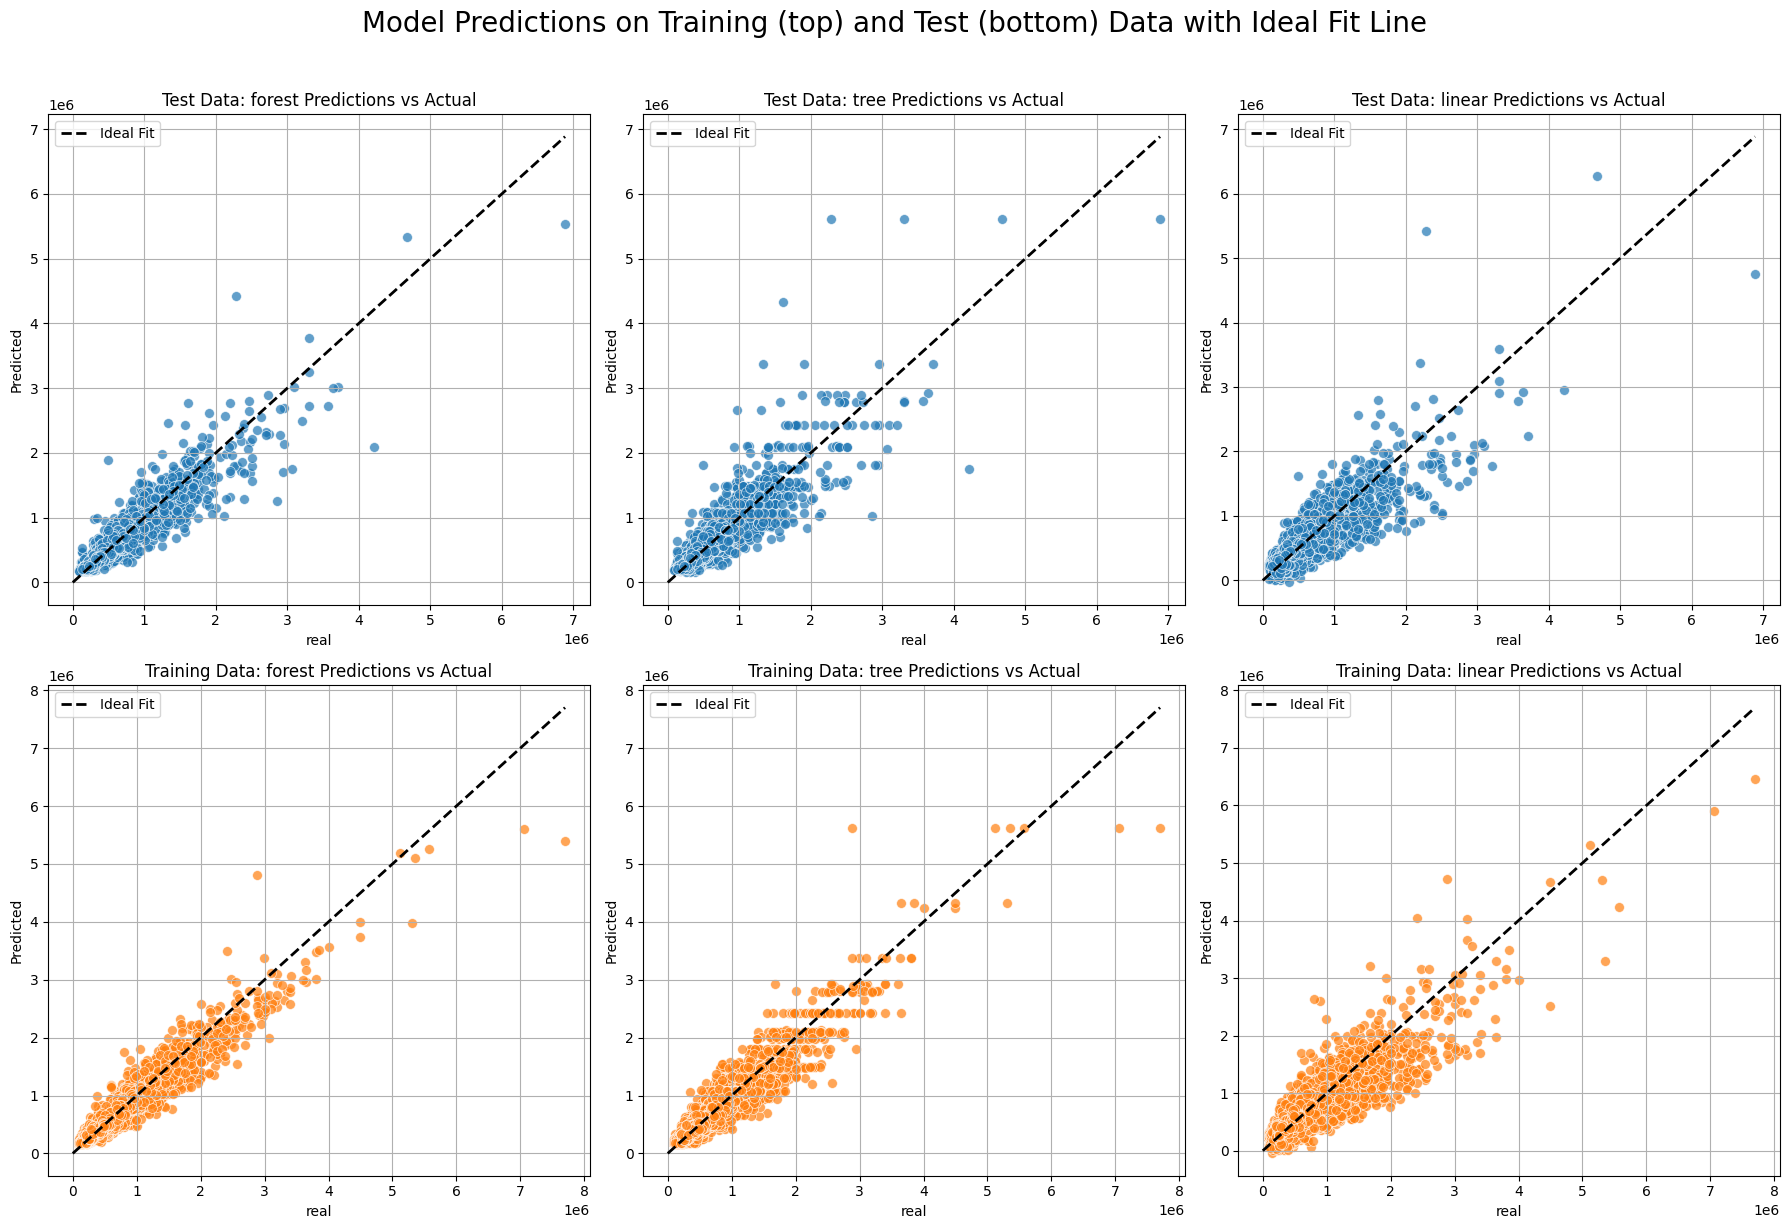

In [26]:
# Convert the data into a long format for Seaborn
result_train_melt = result_train.melt(id_vars='real', var_name='Model', value_name='Predicted')
result_test_melt = result_test.melt(id_vars='real', var_name='Model', value_name='Predicted')

# Set figure size for better readability
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12)) 

# Separate each model's predictions into its own subplot for Test Data (Top Row)
for i, model in enumerate(result_test_melt['Model'].unique()):
    ax = axes[0, i]  # Access the appropriate subplot for test data (top row)
    sns.scatterplot(
        data=result_test_melt[result_test_melt['Model'] == model],
        x='real', y='Predicted', ax=ax, color='tab:blue', s=50, alpha=0.7
    )
    max_val = max(result_test['real'])
    ax.plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=2, label='Ideal Fit')
    ax.set_title(f'Test Data: {model} Predictions vs Actual')
    ax.grid(True)
    ax.legend(loc='upper left')

# Separate each model's predictions into its own subplot for Training Data (Bottom Row)
for i, model in enumerate(result_train_melt['Model'].unique()):
    ax = axes[1, i]  # Access the appropriate subplot for training data (bottom row)
    sns.scatterplot(
        data=result_train_melt[result_train_melt['Model'] == model],
        x='real', y='Predicted', ax=ax, color='tab:orange', s=50, alpha=0.7
    )
    max_val = max(result_train['real'])
    ax.plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=2, label='Ideal Fit')
    ax.set_title(f'Training Data: {model} Predictions vs Actual')
    ax.grid(True)
    ax.legend(loc='upper left')

# Adjust the layout and show the plot
fig.suptitle('Model Predictions on Training (top) and Test (bottom) Data with Ideal Fit Line', size=20, y=1.02)
plt.tight_layout()
plt.show()


In [27]:

# Calculating R^2 and RMSE for each model
metrics = {}
for col in result_test.columns[1:]:
    r2_test = r2_score(result_test['real'], result_test[col])
    rmse_test = np.sqrt(mean_squared_error(result_test['real'], result_test[col]))

    r2_train = r2_score(result_train['real'], result_train[col])
    rmse_train = np.sqrt(mean_squared_error(result_train['real'], result_train[col]))

    metrics[col] = {'R^2_test': r2_test, 'R^2_train': r2_train, 'R^2_std':r2_train - r2_test,
                     'RMSE_test': rmse_test, 'RMSE_train': rmse_train, 'RMSE_std': rmse_test - rmse_train}
metrics_table_transposed = pd.DataFrame(metrics)
metrics_table = pd.DataFrame(metrics).T
metrics_table.reset_index(inplace=True)
metrics_table.rename(columns={'index': 'Model'}, inplace=True)

metrics_table





,Model,R^2_test,R^2_train,R^2_std,RMSE_test,RMSE_train,RMSE_std
0,forest,0.864860,0.918601,0.053741,132715.213241,105587.906218,27127.307023
1,tree,0.786799,0.896820,0.110021,166695.215121,118878.512608,47816.702512
2,linear,0.738266,0.768331,0.030065,184696.451511,178130.979672,6565.471839


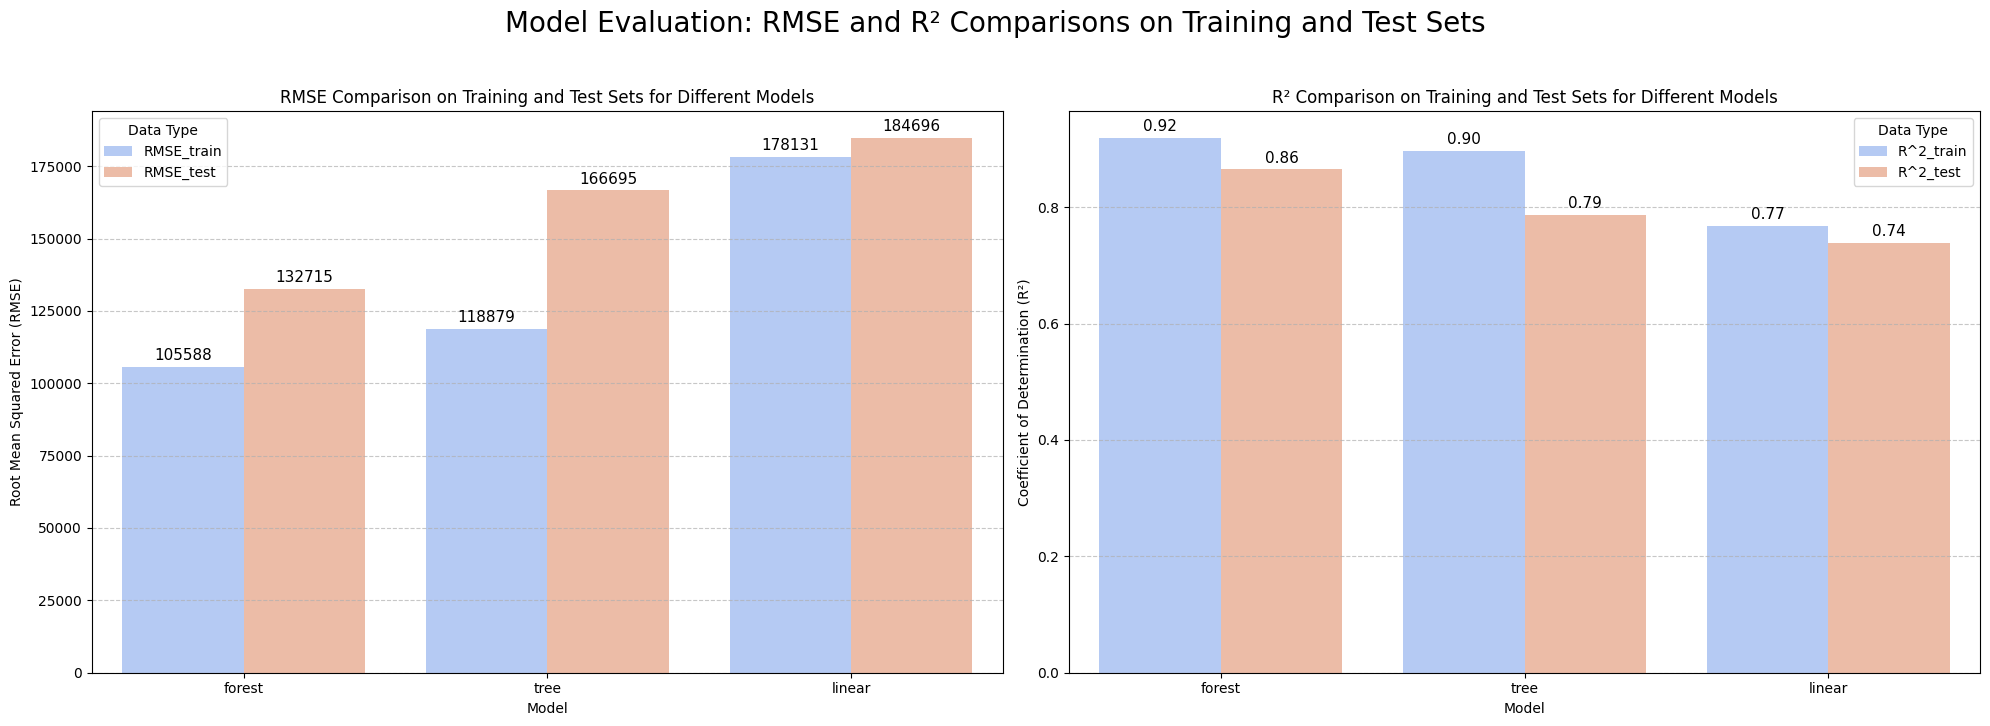

In [37]:
# Step 1: Transform Data for RMSE Plot
rmse_melt = pd.melt(metrics_table, id_vars='Model', value_vars=['RMSE_train', 'RMSE_test'], var_name='DataType', value_name='RMSE')

# Step 2: Transform Data for R² Plot
r2_melt = pd.melt(metrics_table, id_vars='Model', value_vars=['R^2_train', 'R^2_test'], var_name='DataType', value_name='R2')

# Step 3: Create a figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(20, 7))  

# Step 4: Plot RMSE Bar Chart in the First Subplot
barplot_1 = sns.barplot(x='Model', y='RMSE', hue='DataType', data=rmse_melt, palette='coolwarm', ax=ax1)
for p in barplot_1.patches:
    height = p.get_height()
    if height > 0:
        barplot_1.annotate(f'{height:.0f}', (p.get_x() + p.get_width() / 2., height), 
                           ha='center', va='center', fontsize=11, color='black', 
                           xytext=(0, 8), textcoords='offset points')

# Set titles and labels for RMSE chart
ax1.set_title('RMSE Comparison on Training and Test Sets for Different Models')
ax1.set_xlabel('Model')
ax1.set_ylabel('Root Mean Squared Error (RMSE)')
ax1.legend(title='Data Type')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Step 5: Plot R² Bar Chart in the Second Subplot
barplot_2 = sns.barplot(x='Model', y='R2', hue='DataType', data=r2_melt, palette='coolwarm', ax=ax2)
for p in barplot_2.patches:
    height = p.get_height()
    if height > 0:
        barplot_2.annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height), 
                           ha='center', va='center', fontsize=11, color='black', 
                           xytext=(0, 8), textcoords='offset points')

# Set titles and labels for R² chart
ax2.set_title('R² Comparison on Training and Test Sets for Different Models')
ax2.set_xlabel('Model')
ax2.set_ylabel('Coefficient of Determination (R²)')
ax2.legend(title='Data Type')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Step 6: Adjust layout and display the combined figure
fig.suptitle('Model Evaluation: RMSE and R² Comparisons on Training and Test Sets', fontsize=20, y=1.03)
plt.tight_layout()
plt.show()

---
## Feuter importance
Using a linear regression model, we can understand how each parameter impacts the price increase. Specifically, it shows how much the price rises when a parameter increases by one unit.

The graph also provides a visual representation of the feature importance relative to each other, but what is particularly important is that it considers the scale of each feature.

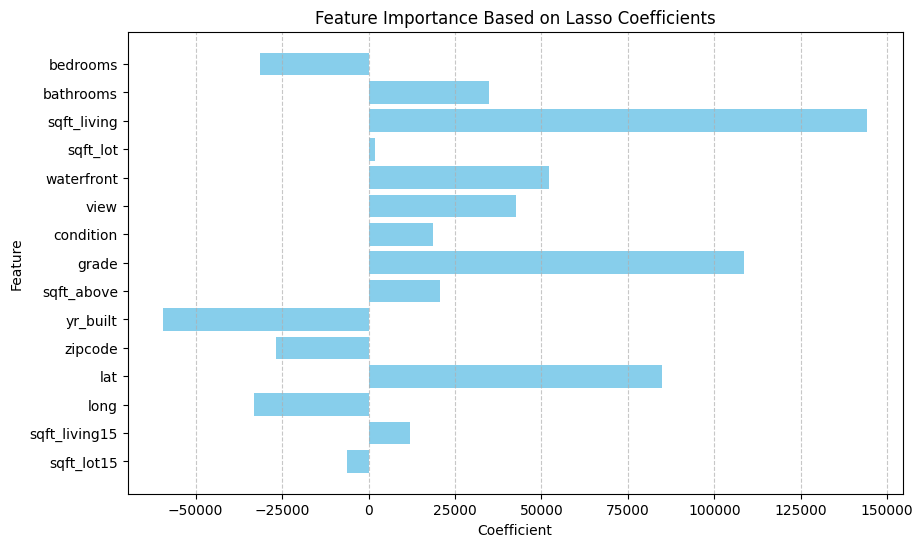

The table below shows the original (unscaled) coefficients for each feature:

                 Feature  Original Coefficient
0               bedrooms         -34951.910148
1              bathrooms          48029.768912
2            sqft_living            157.392336
3               sqft_lot              0.043794
4             waterfront         611736.847156
5                   view          55636.399863
6              condition          28732.618237
7                  grade          92992.868663
8             sqft_above             24.905422
9          sqft_basement              0.000000
10              yr_built          -2066.617136
11               zipcode           -498.115141
12                   lat         613656.617217
13                  long        -236637.401584
14         sqft_living15             17.315807
15            sqft_lot15             -0.230749
16                 month              0.000000
17                  year          26066.048012
18             view_bool     

In [44]:
column_linear_coef = df.drop('price', axis=1).columns

# Initialize the Lasso regression model with a specified alpha value
linear_reg_coef = Lasso(alpha=1000)

# Standardize the feature data
scaler = StandardScaler()
X = scaler.fit_transform(df[column_linear_coef])

# Fit the Lasso model to the standardized data
linear_reg_coef.fit(X, df['price'])

# Retrieve the coefficients and the intercept
coefficients = linear_reg_coef.coef_    # Regression coefficients for each feature
intercept = linear_reg_coef.intercept_  # Intercept term for the model

# Create a table with features and their corresponding coefficients
coef_table = pd.DataFrame({
    'Feature': column_linear_coef,       
    'Coefficient': coefficients         
})

# Filter out zero coefficients and exclude the 'year' feature
coef_table_non_zero = coef_table[(coef_table['Coefficient'] != 0) & (coef_table['Feature'] != 'year')]

# Plot the feature importance based on the Lasso coefficients
plt.figure(figsize=(10, 6))
plt.barh(coef_table_non_zero['Feature'], coef_table_non_zero['Coefficient'], color='skyblue')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Feature Importance Based on Lasso Coefficients')
plt.gca().invert_yaxis()  # Invert the y-axis for better readability
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Retrieve the scaled coefficients from the Lasso model
coef_scaled = linear_reg_coef.coef_

# Get the scale factors from the StandardScaler
scale_factors = scaler.scale_  # Scale factors used during feature standardization

# Calculate the original (unscaled) coefficients by reversing the scaling
original_coefficients = coef_scaled / scale_factors

# Create a DataFrame to display the original coefficients for each feature
original_coef_table = pd.DataFrame({
    'Feature': column_linear_coef,          # Feature names
    'Original Coefficient': original_coefficients  # Corresponding unscaled coefficients
})

# Display the table of original coefficients
print("The table below shows the original (unscaled) coefficients for each feature:\n")
print(original_coef_table)

---
# Conclusion
As we can see, the `Random Forest model` shows very good results in terms of `R²` and `RMSE`, and the small difference between the training and test data indicates the absence of overfitting.

The `Decision Tree` performs slightly worse, but it is also free from overfitting and uses less time and computational resources compared to the `Random Forest`.

Lastly, the `Linear Regression` model demonstrated the weakest performance, which is not surprising, as linear regression can only capture linear relationships. However, there is no overfitting here either, similar to the other models. This is the result of a very thorough feature selection process and careful hyperparameter tuning using GridSearchCV and RandomizedSearchCV.

The smallest `RMSE` value is `$132,715`, which represents about 25% of the average price. This is a reasonably good result within the scope of this project.